<a href="https://colab.research.google.com/github/rodrigocarvajalperez3-max/TFG-Predicci-n-CSTR-con-PI-mediante-RRNN/blob/main/CSTR_bloor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**VALORES EN ESTADO ESTACIONARIO**


MÁXIMO DE Cb_s
Tc_max = 415.00 K
T_max  = 387.43 K
Ca_max = 0.082024
Cb_max = 0.855507
Cc_max = 0.062470

Sensibilidad en el máximo:
dCb_s/dTc_s = -5.062029e-05

PUNTO RECOMENDADO PRODUCCIÓN-CONTROL
Criterio: Cb_s >= 95.0% del máximo
Tc_opt = 395.00 K
T_opt  = 374.65 K
Ca_opt = 0.161810
Cb_opt = 0.815090
Cc_opt = 0.023101
sens_opt = 4.119531e-03


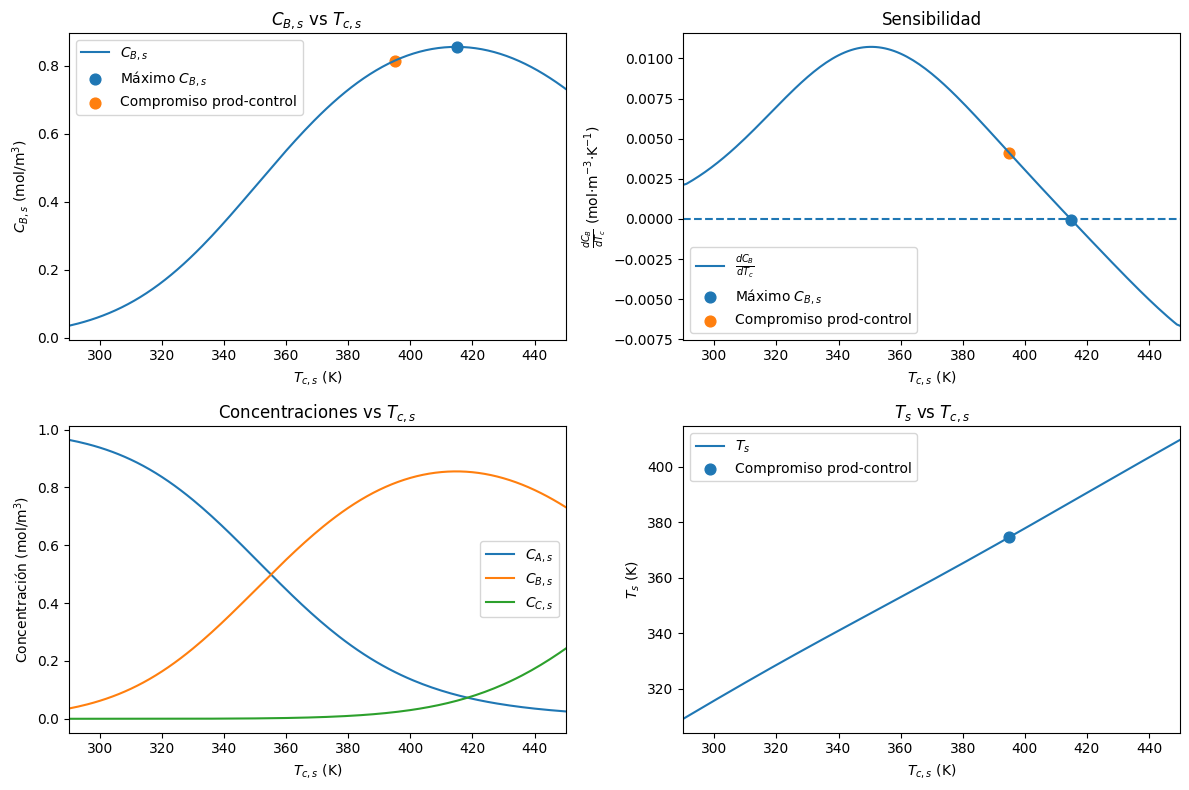

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.optimize import fsolve

# =========================
# Parámetros del proceso
# =========================
Tf   = 350               # K
Cain = 1                 # mol/m3
Fout = 100               # m3/s
rho  = 1000              # kg/m3
Cp   = 0.239             # J/(kg*K)
UA   = 5e4               # W/K
Ha   = 5e3               # J/mol
EaR  = 8750              # K
ka   = 7.2e10            # s^-1
Hb   = 4e3               # J/mol
EbR  = 10750             # K
kb   = 8.2e10            # s^-1

# =========================
# Condiciones fijas
# =========================
V_s = 100.0
Fin_s = Fout

# =========================
# Barrido en Tc_s
# =========================
Tc_vals = []
T_vals  = []
Ca_vals = []
Cb_vals = []
Cc_vals = []

# Guess inicial: [Ca_s, Cb_s, Cc_s, T_s]
guess = [0.8, 0.1, 0.05, 330.0]

for Tc_s in range(290, 451):

    def steady_state(vars_):
        Ca_s, Cb_s, Cc_s, T_s = vars_

        Teff = max(T_s, 1.0)

        ra = ka * math.exp(-EaR / Teff) * Ca_s
        rb = kb * math.exp(-EbR / Teff) * Cb_s

        f = np.zeros(4)

        # dCb/dt = 0
        f[0] = ra - rb - Fin_s * Cb_s / V_s

        # dT/dt = 0
        f[1] = (
            Fin_s * (Tf - T_s) / V_s
            - Ha * ra / (rho * Cp)
            - Hb * rb / (rho * Cp)
            + UA * (Tc_s - T_s) / (V_s * rho * Cp)
        )

        # dCa/dt = 0
        f[2] = Fin_s * (Cain - Ca_s) / V_s - ra

        # dCc/dt = 0
        f[3] = rb - Fin_s * Cc_s / V_s

        return f

    sol = fsolve(steady_state, guess)
    Ca_s, Cb_s, Cc_s, T_s = sol

    # Actualizar guess para mejorar convergencia
    guess = sol

    Tc_vals.append(Tc_s)
    T_vals.append(T_s)
    Ca_vals.append(Ca_s)
    Cb_vals.append(Cb_s)
    Cc_vals.append(Cc_s)

# =========================
# Convertir a arrays
# =========================
Tc_vals = np.array(Tc_vals, dtype=float)
T_vals  = np.array(T_vals, dtype=float)
Ca_vals = np.array(Ca_vals, dtype=float)
Cb_vals = np.array(Cb_vals, dtype=float)
Cc_vals = np.array(Cc_vals, dtype=float)

# =========================
# Máximo de Cb_s
# =========================
idx_max = np.argmax(Cb_vals)
Cb_max = Cb_vals[idx_max]

Tc_max = Tc_vals[idx_max]
T_max  = T_vals[idx_max]
Ca_max = Ca_vals[idx_max]
Cb_max_val = Cb_vals[idx_max]
Cc_max = Cc_vals[idx_max]

print("\n=========================")
print("MÁXIMO DE Cb_s")
print("=========================")
print(f"Tc_max = {Tc_max:.2f} K")
print(f"T_max  = {T_max:.2f} K")
print(f"Ca_max = {Ca_max:.6f}")
print(f"Cb_max = {Cb_max_val:.6f}")
print(f"Cc_max = {Cc_max:.6f}")

# =========================
# Sensibilidad dCb_s/dTc_s
# =========================
dCb_dTc = np.gradient(Cb_vals, Tc_vals)

print("\nSensibilidad en el máximo:")
print(f"dCb_s/dTc_s = {dCb_dTc[idx_max]:.6e}")

# =========================
# Punto de compromiso producción-control
# Criterio:
#   - producción al menos del 95% del máximo
#   - dentro de esos, elegir el de mayor |dCb/dTc|
# =========================
frac_prod = 0.95
mask = Cb_vals >= frac_prod * Cb_max
idx_candidates = np.where(mask)[0]

if len(idx_candidates) == 0:
    print("\nNo hay candidatos para el criterio elegido.")
    Tc_opt = None
    T_opt  = None
    Ca_opt = None
    Cb_opt = None
    Cc_opt = None
    sens_opt = None
    idx_best = None
else:
    idx_best = idx_candidates[np.argmax(np.abs(dCb_dTc[idx_candidates]))]

    # Guardar punto de compromiso en variables
    Tc_opt = Tc_vals[idx_best]
    T_opt  = T_vals[idx_best]
    Ca_opt = Ca_vals[idx_best]
    Cb_opt = Cb_vals[idx_best]
    Cc_opt = Cc_vals[idx_best]
    sens_opt = dCb_dTc[idx_best]

    print("\n=========================")
    print("PUNTO RECOMENDADO PRODUCCIÓN-CONTROL")
    print("=========================")
    print(f"Criterio: Cb_s >= {frac_prod*100:.1f}% del máximo")
    print(f"Tc_opt = {Tc_opt:.2f} K")
    print(f"T_opt  = {T_opt:.2f} K")
    print(f"Ca_opt = {Ca_opt:.6f}")
    print(f"Cb_opt = {Cb_opt:.6f}")
    print(f"Cc_opt = {Cc_opt:.6f}")
    print(f"sens_opt = {sens_opt:.6e}")

# =========================
# SUBPLOTS
# =========================

import zipfile
from google.colab import files

# =========================
# FUNCIÓN AUXILIAR
# =========================
def ajustar_solo_x(ax, x):
    ax.set_xlim(np.min(x), np.max(x))
    ax.margins(x=0)

# =========================
# FIGURA PRINCIPAL
# =========================
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# --- Subplot 1 ---
axs[0, 0].plot(Tc_vals, Cb_vals, label=r"$C_{B,s}$")
axs[0, 0].scatter(Tc_vals[idx_max], Cb_vals[idx_max],
                  label=r"Máximo $C_{B,s}$", s=60)

if idx_best is not None:
    axs[0, 0].scatter(
        Tc_vals[idx_best], Cb_vals[idx_best],
        label="Compromiso prod-control", s=60
    )

axs[0, 0].set_xlabel(r"$T_{c,s}$ (K)")
axs[0, 0].set_ylabel(r"$C_{B,s}$ (mol/m$^3$)")
axs[0, 0].set_title(r"$C_{B,s}$ vs $T_{c,s}$")
axs[0, 0].grid(False)
axs[0, 0].legend()
ajustar_solo_x(axs[0, 0], Tc_vals)

# --- Subplot 2 ---
axs[0, 1].plot(Tc_vals, dCb_dTc, label=r"$\frac{dC_B}{dT_c}$")
axs[0, 1].axhline(0, linestyle="--")

axs[0, 1].scatter(Tc_vals[idx_max], dCb_dTc[idx_max],
                  label=r"Máximo $C_{B,s}$", s=60)

if idx_best is not None:
    axs[0, 1].scatter(
        Tc_vals[idx_best], dCb_dTc[idx_best],
        label="Compromiso prod-control", s=60
    )

axs[0, 1].set_xlabel(r"$T_{c,s}$ (K)")
axs[0, 1].set_ylabel(r"$\frac{dC_B}{dT_c}$ (mol·m$^{-3}$·K$^{-1}$)")
axs[0, 1].set_title("Sensibilidad")
axs[0, 1].grid(False)
axs[0, 1].legend()
ajustar_solo_x(axs[0, 1], Tc_vals)

# --- Subplot 3 ---
axs[1, 0].plot(Tc_vals, Ca_vals, label=r"$C_{A,s}$")
axs[1, 0].plot(Tc_vals, Cb_vals, label=r"$C_{B,s}$")
axs[1, 0].plot(Tc_vals, Cc_vals, label=r"$C_{C,s}$")

axs[1, 0].set_xlabel(r"$T_{c,s}$ (K)")
axs[1, 0].set_ylabel(r"Concentración (mol/m$^3$)")
axs[1, 0].set_title(r"Concentraciones vs $T_{c,s}$")
axs[1, 0].grid(False)
axs[1, 0].legend()
ajustar_solo_x(axs[1, 0], Tc_vals)

# --- Subplot 4 ---
axs[1, 1].plot(Tc_vals, T_vals, label=r"$T_s$")

if idx_best is not None:
    axs[1, 1].scatter(
        Tc_vals[idx_best], T_vals[idx_best],
        label="Compromiso prod-control", s=60
    )

axs[1, 1].set_xlabel(r"$T_{c,s}$ (K)")
axs[1, 1].set_ylabel(r"$T_s$ (K)")
axs[1, 1].set_title(r"$T_s$ vs $T_{c,s}$")
axs[1, 1].grid(False)
axs[1, 1].legend()
ajustar_solo_x(axs[1, 1], Tc_vals)

plt.tight_layout()
plt.show()







In [ ]:
# =========================
# GUARDAR SUBPLOTS
# =========================
archivos = []

# --- Subplot 1 ---
fig1, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(Tc_vals, Cb_vals, label=r"$C_{B,s}$")
ax1.scatter(Tc_vals[idx_max], Cb_vals[idx_max],
            label=r"Máximo $C_{B,s}$", s=60)

if idx_best is not None:
    ax1.scatter(Tc_vals[idx_best], Cb_vals[idx_best],
                label="Compromiso prod-control", s=60)

ax1.set_xlabel(r"$T_{c,s}$ (K)")
ax1.set_ylabel(r"$C_{B,s}$ (mol/m$^3$)")
ax1.set_title(r"$C_{B,s}$ vs $T_{c,s}$")
ax1.grid(False)
ax1.legend()
ajustar_solo_x(ax1, Tc_vals)

nombre1 = "subplot_1_Cb_vs_Tc.png"
fig1.tight_layout()
fig1.savefig(nombre1, dpi=300, bbox_inches="tight")
plt.close(fig1)
archivos.append(nombre1)

# --- Subplot 2 ---
fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.plot(Tc_vals, dCb_dTc, label=r"$\frac{dC_B}{dT_c}$")
ax2.axhline(0, linestyle="--")
ax2.scatter(Tc_vals[idx_max], dCb_dTc[idx_max],
            label=r"Máximo $C_B$", s=60)

if idx_best is not None:
    ax2.scatter(Tc_vals[idx_best], dCb_dTc[idx_best],
                label="Compromiso prod-control", s=60)

ax2.set_xlabel(r"$T_{c,s}$ (K)")
ax2.set_ylabel(r"$\frac{dC_B}{dT_c}$ (mol·m$^{-3}$·K$^{-1}$)")
ax2.set_title("Sensibilidad")
ax2.grid(False)
ax2.legend()
ajustar_solo_x(ax2, Tc_vals)

nombre2 = "subplot_2_sensibilidad.png"
fig2.tight_layout()
fig2.savefig(nombre2, dpi=300, bbox_inches="tight")
plt.close(fig2)
archivos.append(nombre2)

# --- Subplot 3 ---
fig3, ax3 = plt.subplots(figsize=(6, 4))
ax3.plot(Tc_vals, Ca_vals, label=r"$C_{A,s}$")
ax3.plot(Tc_vals, Cb_vals, label=r"$C_{B,s}$")
ax3.plot(Tc_vals, Cc_vals, label=r"$C_{C,s}$")

ax3.set_xlabel(r"$T_{c,s}$ (K)")
ax3.set_ylabel(r"Concentración (mol/m$^3$)")
ax3.set_title(r"Concentraciones vs $T_{c,s}$")
ax3.grid(False)
ax3.legend()
ajustar_solo_x(ax3, Tc_vals)

nombre3 = "subplot_3_concentraciones.png"
fig3.tight_layout()
fig3.savefig(nombre3, dpi=300, bbox_inches="tight")
plt.close(fig3)
archivos.append(nombre3)

# --- Subplot 4 ---
fig4, ax4 = plt.subplots(figsize=(6, 4))
ax4.plot(Tc_vals, T_vals, label=r"$T_s$")

if idx_best is not None:
    ax4.scatter(Tc_vals[idx_best], T_vals[idx_best],
                label="Compromiso prod-control", s=60)

ax4.set_xlabel(r"$T_{c,s}$ (K)")
ax4.set_ylabel(r"$T_s$ (K)")
ax4.set_title(r"$T_s$ vs $T_{c,s}$")
ax4.grid(False)
ax4.legend()
ajustar_solo_x(ax4, Tc_vals)

nombre4 = "subplot_4_temperatura.png"
fig4.tight_layout()
fig4.savefig(nombre4, dpi=300, bbox_inches="tight")
plt.close(fig4)
archivos.append(nombre4)
# =========================
# ZIP Y DESCARGA
# =========================
zip_name = "subplots_CSTR.zip"

with zipfile.ZipFile(zip_name, "w") as zipf:
    for archivo in archivos:
        zipf.write(archivo)

files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**SIMULACIÓN CSTR_ BLOOR CON PI**

True
The solver successfully reached the end of the integration interval.

PUNTO DE OPERACIÓN USADO
Tc_s  = 395.00 K
T_s   = 374.65 K
Ca_s  = 0.161810
Cb_s  = 0.815090
Cc_s  = 0.023101
V_s   = 100.00
Fin_s = 100.00


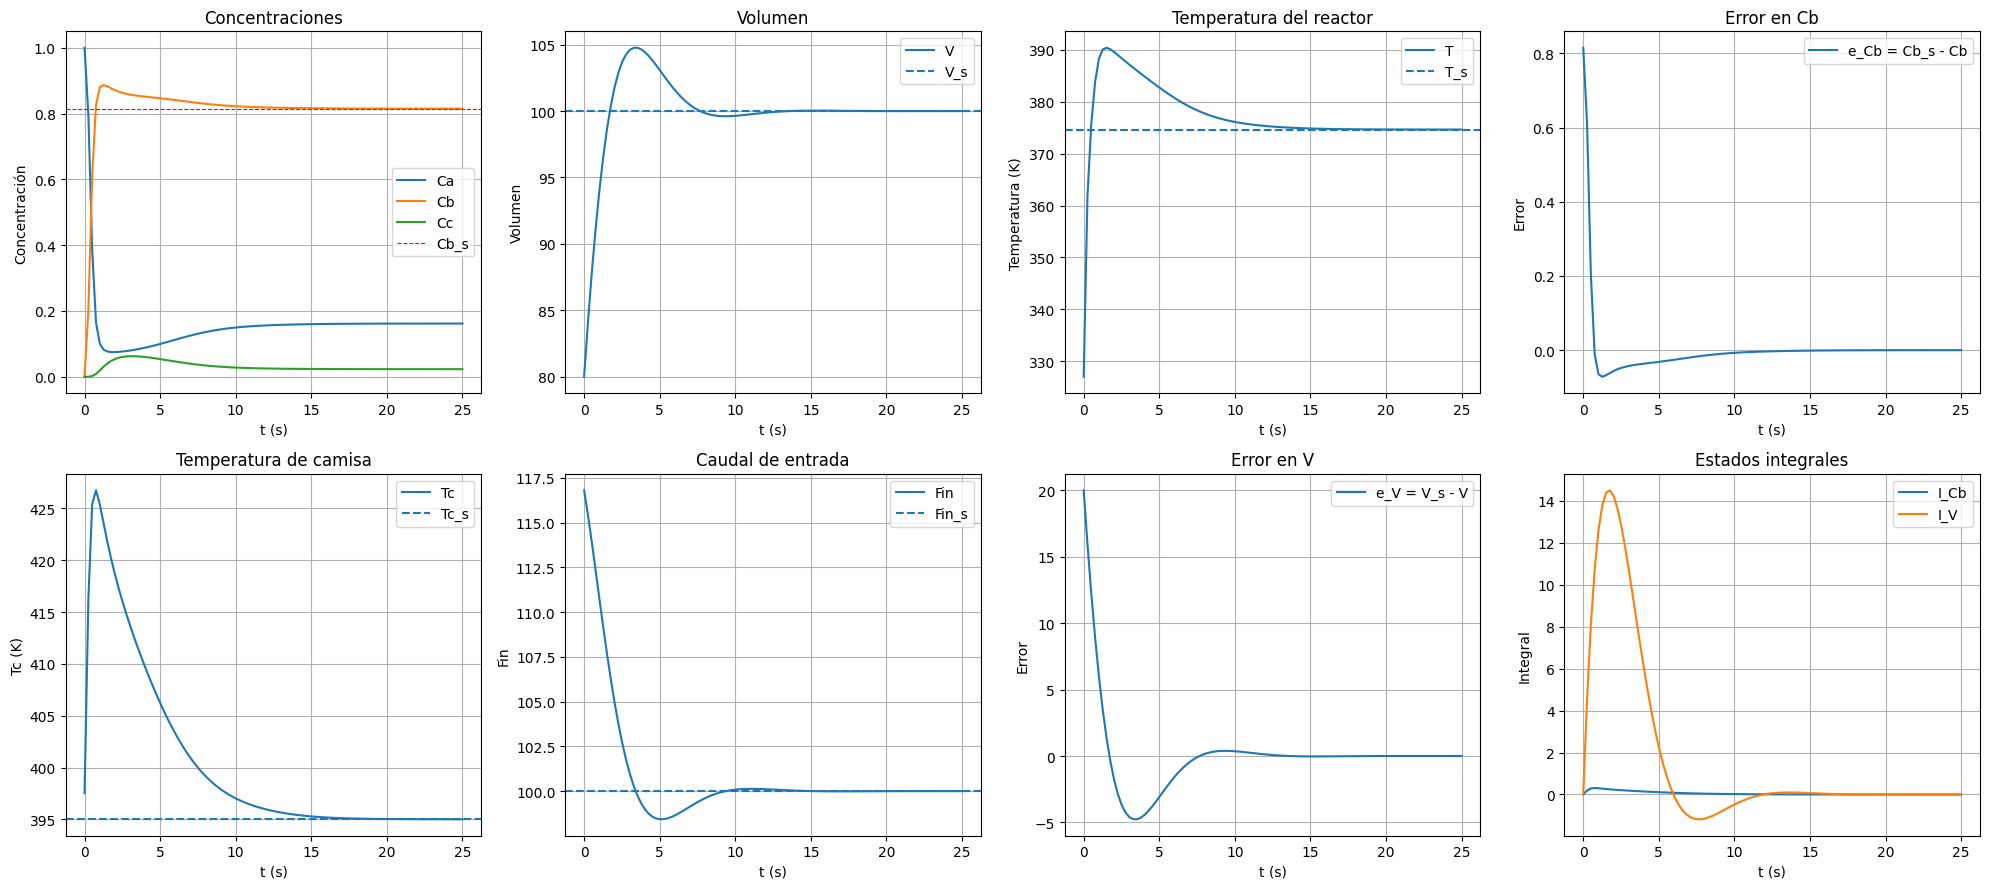

Dimensiones: (7, 100)


In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import math



# =========================
# Parámetros del proceso
# =========================
Tf   = 350
Cain = 1
Fout = 100
rho  = 1000
Cp   = 0.239
UA   = 5e4
Ha   = 5e3
EaR  = 8750
ka   = 7.2e10
Hb   = 4e3
EbR  = 10750
kb   = 8.2e10

# =========================
# Comprobación básica
# =========================
if Tc_opt is None:
    raise ValueError("No existe punto de compromiso. Ejecuta antes el código de estados estacionarios.")

# =========================
# Setpoints y bias desde el punto óptimo
# =========================
Cb_s = Cb_opt
V_s  = 100.0
T_s  = T_opt
Ca_s = Ca_opt
Cc_s = Cc_opt

Tc_s  = Tc_opt
Fin_s = Fout

# =========================
# Ganancias PI
# =========================
Kc_Cb   = 3.09
tauI_Cb = 0.03

Kc_Fin   = 0.84
tauI_Fin = 1.85

# =========================
# Iniciales DEL SISTEMA
# =========================
Cb0 = 0.0
T0  = 327.0
V0  = 80.0
Ca0 = 1.0
Cc0 = 0.0
I_Cb0 = 0.0
I_V0  = 0.0

y0 = [Cb0, T0, V0, Ca0, Cc0, I_Cb0, I_V0]


def CSTR_PI(t, y):
    Cb, T, V, Ca, Cc, I_Cb, I_V = y

    Veff = max(V, 1e-6)
    Teff = max(T, 1.0)

    # Errores
    e_Cb = Cb_s - Cb
    e_V  = V_s - V

    # Controlador PI sin saturación
    Tc  = float(Tc_s  + Kc_Cb  * (e_Cb + I_Cb / tauI_Cb))
    Fin = float(Fin_s + Kc_Fin * (e_V  + I_V  / tauI_Fin))

    # Cinética
    ra = ka * math.exp(-EaR / Teff) * Ca
    rb = kb * math.exp(-EbR / Teff) * Cb

    # Ecuaciones del reactor
    dCb = ra - rb - Fin * Cb / Veff

    dT = (
        Fin * (Tf - T) / Veff
        - Ha * ra / (rho * Cp)
        - Hb * rb / (rho * Cp)
        + UA * (Tc - T) / (Veff * rho * Cp)
    )

    dV  = Fin - Fout
    dCa = Fin * (Cain - Ca) / Veff - ra
    dCc = rb - Fin * Cc / Veff

    # Integrales del PI
    dI_Cb = e_Cb
    dI_V  = e_V

    return [dCb, dT, dV, dCa, dCc, dI_Cb, dI_V]


# =========================
# Simulación
# =========================
t0 = 0.0
tf = 25.0
t_eval = np.linspace(t0, tf, 100)

sol = solve_ivp(
    CSTR_PI,
    (t0, tf),
    y0,
    method="BDF",
    t_eval=t_eval
)

print(sol.success)
print(sol.message)

# =========================
# Reconstrucción de variables
# =========================
t    = sol.t
Cb   = sol.y[0]
T    = sol.y[1]
V    = sol.y[2]
Ca   = sol.y[3]
Cc   = sol.y[4]
I_Cb = sol.y[5]
I_V  = sol.y[6]

e_Cb = Cb_s - Cb
e_V  = V_s - V

Tc_unsat  = Tc_s  + Kc_Cb  * (e_Cb + I_Cb / tauI_Cb)
Fin_unsat = Fin_s + Kc_Fin * (e_V  + I_V  / tauI_Fin)

Tc  = Tc_unsat
Fin = Fin_unsat

# =========================
# Mostrar punto de operación usado
# =========================
print("\n=========================")
print("PUNTO DE OPERACIÓN USADO")
print("=========================")
print(f"Tc_s  = {Tc_s:.2f} K")
print(f"T_s   = {T_s:.2f} K")
print(f"Ca_s  = {Ca_s:.6f}")
print(f"Cb_s  = {Cb_s:.6f}")
print(f"Cc_s  = {Cc_s:.6f}")
print(f"V_s   = {V_s:.2f}")
print(f"Fin_s = {Fin_s:.2f}")

# =========================
# Gráficas en subplots
# =========================
fig, axs = plt.subplots(2, 4, figsize=(20, 9))

# --- Concentraciones ---
axs[0, 0].plot(t, Ca, label="Ca")
axs[0, 0].plot(t, Cb, label="Cb")
axs[0, 0].plot(t, Cc, label="Cc")
#axs[0, 0].axhline(Ca_s, linestyle="--", label="Ca_s")
axs[0, 0].axhline(Cb_s, linestyle="--", color="red", linewidth=0.8, label="Cb_s")
#axs[0, 0].axhline(Cc_s, linestyle="--", label="Cc_s")
axs[0, 0].set_xlabel("t (s)")
axs[0, 0].set_ylabel("Concentración")
axs[0, 0].set_title("Concentraciones")
axs[0, 0].grid(True)
axs[0, 0].legend()

# --- Volumen ---
axs[0, 1].plot(t, V, label="V")
axs[0, 1].axhline(V_s, linestyle="--", label="V_s")
axs[0, 1].set_xlabel("t (s)")
axs[0, 1].set_ylabel("Volumen")
axs[0, 1].set_title("Volumen")
axs[0, 1].grid(True)
axs[0, 1].legend()

# --- Temperatura del reactor ---
axs[0, 2].plot(t, T, label="T")
axs[0, 2].axhline(T_s, linestyle="--", label="T_s")
axs[0, 2].set_xlabel("t (s)")
axs[0, 2].set_ylabel("Temperatura (K)")
axs[0, 2].set_title("Temperatura del reactor")
axs[0, 2].grid(True)
axs[0, 2].legend()

# --- Error de Cb ---
axs[0, 3].plot(t, e_Cb, label="e_Cb = Cb_s - Cb")
axs[0, 3].set_xlabel("t (s)")
axs[0, 3].set_ylabel("Error")
axs[0, 3].set_title("Error en Cb")
axs[0, 3].grid(True)
axs[0, 3].legend()

# --- Tc en subplot propio ---
axs[1, 0].plot(t, Tc, label="Tc")
axs[1, 0].axhline(Tc_s, linestyle="--", label="Tc_s")
axs[1, 0].set_xlabel("t (s)")
axs[1, 0].set_ylabel("Tc (K)")
axs[1, 0].set_title("Temperatura de camisa")
axs[1, 0].grid(True)
axs[1, 0].legend()

# --- Fin en subplot propio ---
axs[1, 1].plot(t, Fin, label="Fin")
axs[1, 1].axhline(Fin_s, linestyle="--", label="Fin_s")
axs[1, 1].set_xlabel("t (s)")
axs[1, 1].set_ylabel("Fin")
axs[1, 1].set_title("Caudal de entrada")
axs[1, 1].grid(True)
axs[1, 1].legend()

# --- Error de volumen ---
axs[1, 2].plot(t, e_V, label="e_V = V_s - V")
axs[1, 2].set_xlabel("t (s)")
axs[1, 2].set_ylabel("Error")
axs[1, 2].set_title("Error en V")
axs[1, 2].grid(True)
axs[1, 2].legend()

# --- Integrales ---
axs[1, 3].plot(t, I_Cb, label="I_Cb")
axs[1, 3].plot(t, I_V, label="I_V")
axs[1, 3].set_xlabel("t (s)")
axs[1, 3].set_ylabel("Integral")
axs[1, 3].set_title("Estados integrales")
axs[1, 3].grid(True)
axs[1, 3].legend()

plt.tight_layout()
plt.show()

print("Dimensiones:", sol.y.shape)

**DESCARGAR GRÁFICOS**

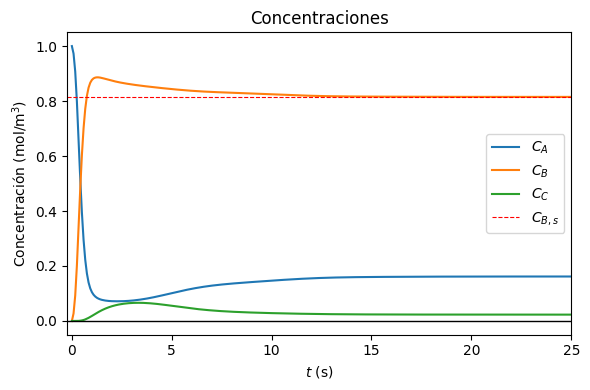

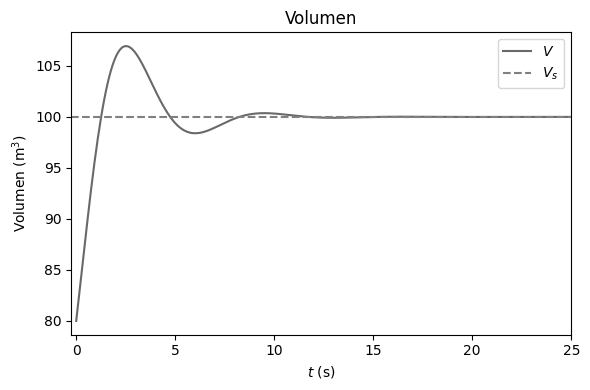

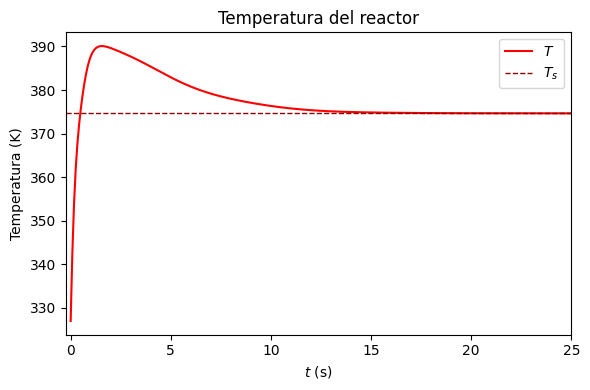

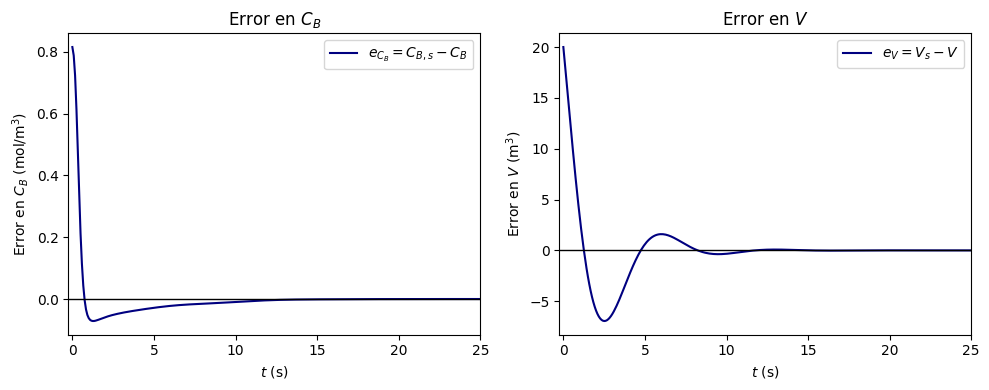

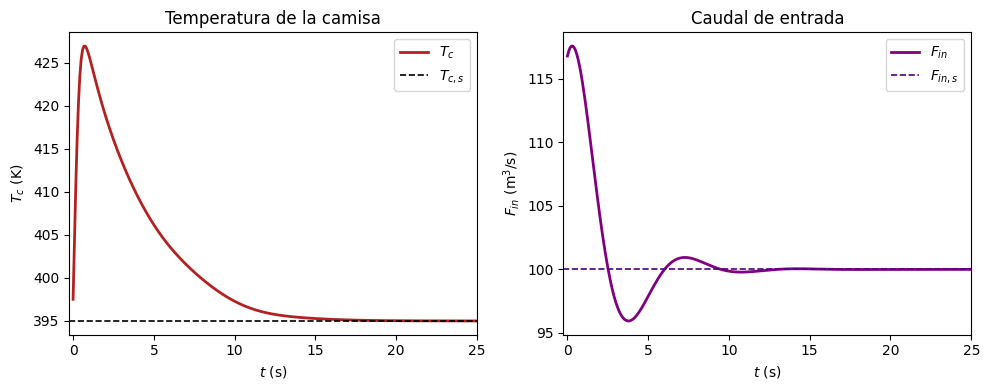

In [ ]:
import matplotlib.pyplot as plt
import zipfile
import os

# =========================================================
# ESTILO ESTÁNDAR DE MATPLOTLIB
# =========================================================
plt.rcdefaults()

# Carpeta donde se guardarán las figuras
output_dir = "figuras_cstr"
os.makedirs(output_dir, exist_ok=True)

saved_files = []

# Márgenes del eje x
x_left = t[0] - 0.01 * (t[-1] - t[0])   # pequeñísimo margen a la izquierda
x_right = t[-1]                         # corte justo al final por la derecha

# =========================================================
# 1. CONCENTRACIONES
# =========================================================
plt.figure(figsize=(6,4))
plt.plot(t, Ca, label=r"$C_A$")
plt.plot(t, Cb, label=r"$C_B$")
plt.plot(t, Cc, label=r"$C_C$")
plt.axhline(Cb_s, linestyle="--", color="red", linewidth=0.8, label=r"$C_{B,s}$")

# Línea del eje en y = 0
plt.axhline(0, color="black", linestyle="-", linewidth=1)

plt.xlabel(r"$t$ (s)")
plt.ylabel(r"Concentración (mol/m$^3$)")
plt.title("Concentraciones")
plt.xlim(x_left, x_right)

# Forzar a que el eje incluya el 0
ymin = min(Ca.min(), Cb.min(), Cc.min(), 0)
ymax = max(Ca.max(), Cb.max(), Cc.max())
plt.ylim(ymin - 0.05*(ymax - ymin + 1e-9), ymax + 0.05*(ymax - ymin + 1e-9))

plt.grid(False)
plt.legend()
plt.tight_layout()

path1 = os.path.join(output_dir, "01_concentraciones.png")
plt.savefig(path1, dpi=300, bbox_inches="tight")
saved_files.append(path1)
plt.show()
plt.close()

# =========================================================
# 2. VOLUMEN
# =========================================================
plt.figure(figsize=(6,4))

plt.plot(t, V, color="dimgray", label=r"$V$")


plt.axhline(V_s, linestyle="--", color="gray", label=r"$V_s$")

plt.xlabel(r"$t$ (s)")
plt.ylabel(r"Volumen (m$^3$)")
plt.title("Volumen")
plt.xlim(x_left, x_right)

plt.grid(False)
plt.legend()
plt.tight_layout()

path2 = os.path.join(output_dir, "02_volumen.png")
plt.savefig(path2, dpi=300, bbox_inches="tight")
saved_files.append(path2)
plt.show()
plt.close()

# =========================================================
# 3. TEMPERATURA DEL REACTOR
# =========================================================
plt.figure(figsize=(6,4))
plt.plot(t, T, color="red", label=r"$T$")
plt.axhline(T_s, linestyle="--", color="darkred", linewidth=1, label=r"$T_s$")
plt.xlabel(r"$t$ (s)")
plt.ylabel("Temperatura (K)")
plt.title("Temperatura del reactor")
plt.xlim(x_left, x_right)
plt.grid(False)
plt.legend()
plt.tight_layout()

path3 = os.path.join(output_dir, "03_temperatura_reactor.png")
plt.savefig(path3, dpi=300, bbox_inches="tight")
saved_files.append(path3)
plt.show()
plt.close()

# =========================================================
# 6. ERRORES DE Cb Y V EN GRÁFICOS DISTINTOS, MISMA IMAGEN
# =========================================================
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# --- Error de Cb ---
axs[0].plot(t, e_Cb, color="navy", label=r"$e_{C_B}=C_{B,s}-C_B$")
axs[0].axhline(0, color="black", linestyle="-", linewidth=1)
axs[0].set_xlabel(r"$t$ (s)")
axs[0].set_ylabel(r"Error en $C_B$ (mol/m$^3$)")
axs[0].set_title(r"Error en $C_B$")
axs[0].set_xlim(x_left, x_right)

# Forzar a que se vea la zona negativa
ymin_cb = min(e_Cb.min(), 0) - 0.05 * (e_Cb.max() - e_Cb.min() + 1e-9)
ymax_cb = max(e_Cb.max(), 0) + 0.05 * (e_Cb.max() - e_Cb.min() + 1e-9)
axs[0].set_ylim(ymin_cb, ymax_cb)

axs[0].grid(False)
axs[0].legend()

# --- Error de V ---
axs[1].plot(t, e_V, color="navy", label=r"$e_V=V_s-V$")
axs[1].axhline(0, color="black", linestyle="-", linewidth=1)
axs[1].set_xlabel(r"$t$ (s)")
axs[1].set_ylabel(r"Error en $V$ (m$^3$)")
axs[1].set_title(r"Error en $V$")
axs[1].set_xlim(x_left, x_right)

# Forzar a que se vea la zona negativa
ymin_v = min(e_V.min(), 0) - 0.05 * (e_V.max() - e_V.min() + 1e-9)
ymax_v = max(e_V.max(), 0) + 0.05 * (e_V.max() - e_V.min() + 1e-9)
axs[1].set_ylim(ymin_v, ymax_v)

axs[1].grid(False)
axs[1].legend()

plt.tight_layout()

path6 = os.path.join(output_dir, "06_errores_Cb_V_lateral.png")
plt.savefig(path6, dpi=300, bbox_inches="tight")
saved_files.append(path6)
plt.show()
plt.close()

# =========================================================
# 5. Tc Y Fin EN GRÁFICOS DISTINTOS, MISMA IMAGEN
# =========================================================
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# --- Tc ---
axs[0].plot(t, Tc, color="firebrick", linewidth=2, label=r"$T_c$")
axs[0].axhline(Tc_s, linestyle="--", color="black", linewidth=1.2, label=r"$T_{c,s}$")
axs[0].set_xlabel(r"$t$ (s)")
axs[0].set_ylabel(r"$T_c$ (K)")
axs[0].set_title("Temperatura de la camisa")
axs[0].set_xlim(x_left, x_right)

# Ajuste del eje y para que la variación se aprecie mejor
ymin_tc = min(Tc.min(), Tc_s)
ymax_tc = max(Tc.max(), Tc_s)
margen_tc = 0.05 * (ymax_tc - ymin_tc + 1e-9)
axs[0].set_ylim(ymin_tc - margen_tc, ymax_tc + margen_tc)

axs[0].grid(False)
axs[0].legend()

# --- Fin ---
axs[1].plot(t, Fin, color="purple", linewidth=2, label=r"$F_{in}$")
axs[1].axhline(Fin_s, linestyle="--", color="indigo", linewidth=1.2, label=r"$F_{in,s}$")
axs[1].set_xlabel(r"$t$ (s)")
axs[1].set_ylabel(r"$F_{in}$ (m$^3$/s)")
axs[1].set_title("Caudal de entrada")
axs[1].set_xlim(x_left, x_right)

# Ajuste del eje y para Fin
ymin_fin = min(Fin.min(), Fin_s)
ymax_fin = max(Fin.max(), Fin_s)
margen_fin = 0.05 * (ymax_fin - ymin_fin + 1e-9)
axs[1].set_ylim(ymin_fin - margen_fin, ymax_fin + margen_fin)

axs[1].grid(False)
axs[1].legend()

plt.tight_layout()

path5 = os.path.join(output_dir, "05_Tc_y_Fin_lateral.png")
plt.savefig(path5, dpi=300, bbox_inches="tight")
saved_files.append(path5)
plt.show()
plt.close()





# =========================================================
# CREAR ARCHIVO ZIP
# =========================================================
zip_path = "figuras_cstr.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for file in saved_files:
        zipf.write(file, arcname=os.path.basename(file))



In [ ]:
# =========================================================
# DESCARGA AUTOMÁTICA EN GOOGLE COLAB
# =========================================================
try:
    from google.colab import files
    files.download(zip_path)
except:
    print(f"Archivo ZIP guardado en: {zip_path}")

# =========================================================
# DIMENSIONES DE LA SOLUCIÓN
# =========================================================
print("Dimensiones:", sol.y.shape)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dimensiones: (7, 300)


**MOSTRAR DATOS CON PANDA**

In [ ]:
import pandas as pd

df = pd.DataFrame(sol.y.T, columns=["Cb", "T", "V", "Ca", "Cc", "I_Cb", "I_V"])
print(df.head(100))

df["t"] = sol.t   # añade el tiempo al DataFrame

df[(df["t"] > 20) & (df["t"] < 25)]

          Cb           T           V        Ca        Cc      I_Cb       I_V
0   0.000000  327.000000   80.000000  1.000000  0.000000  0.000000  0.000000
1   0.027328  342.471607   81.422402  0.972670  0.000001  0.067202  1.612982
2   0.092154  353.752362   82.872205  0.907826  0.000019  0.130638  3.105844
3   0.200852  361.792866   84.337868  0.799040  0.000109  0.186838  4.476757
4   0.338577  367.554727   85.808557  0.661039  0.000384  0.232581  5.724814
..       ...         ...         ...       ...       ...       ...       ...
95  0.830500  378.049003   99.793533  0.135604  0.033896  0.048549  0.602641
96  0.830290  377.962830   99.856257  0.136123  0.033587  0.047269  0.617273
97  0.830080  377.878472   99.915685  0.136630  0.033289  0.046008  0.626798
98  0.829870  377.795839   99.971643  0.137127  0.033003  0.044764  0.631495
99  0.829658  377.714847  100.023990  0.137615  0.032727  0.043537  0.631659

[100 rows x 7 columns]


,Cb,T,V,Ca,Cc,I_Cb,I_V,t
240,0.815208,374.672736,99.995459,0.161611,0.023181,0.000291,-0.003454,20.066890
241,0.815203,374.671915,99.995507,0.161620,0.023177,0.000281,-0.003077,20.150502
242,0.815198,374.671129,99.995581,0.161627,0.023174,0.000272,-0.002705,20.234114
243,0.815194,374.670377,99.995680,0.161635,0.023172,0.000263,-0.002340,20.317726
244,0.815190,374.669657,99.995800,0.161641,0.023169,0.000255,-0.001985,20.401338
245,0.815186,374.668969,99.995940,0.161648,0.023166,0.000246,-0.001640,20.484950
246,0.815182,374.668311,99.996098,0.161654,0.023164,0.000239,-0.001308,20.568562
247,0.815179,374.667681,99.996271,0.161660,0.023161,0.000231,-0.000989,20.652174
248,0.815175,374.667079,99.996457,0.161666,0.023159,0.000224,-0.000685,20.735786
249,0.815172,374.666501,99.996654,0.161671,0.023157,0.000217,-0.000398,20.819398
